# Used-car price prediction: regression models

**Use case.** A first-time buyer or a small dealer enters a car's basic facts (year, mileage, make, condition and so on) and gets an estimated fair asking price in US dollars. They use it to check whether a listing is overpriced before they negotiate or buy. This supports the mission of making vehicle purchases more transparent and affordable for ordinary buyers.

**Dataset.** Craigslist used-vehicle listings (`vehicles.csv`, about 295,000 rows, 40 columns). The target is `price`, a continuous number.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import os
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, joblib
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import SGDRegressor, LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error
RNG = 42

## 1. Load and clean the data

In [2]:
KEEP = ["price","year","odometer","manufacturer","condition","cylinders","fuel","transmission",
        "drive","type","title_status","seller_type","paint_color","state","image_count"]
raw = pd.read_csv("vehicles.csv", usecols=KEEP, low_memory=False)
print("raw shape:", raw.shape)
raw["price"] = pd.to_numeric(raw["price"], errors="coerce")
df = raw.dropna(subset=["price","year","odometer","manufacturer"]).copy()
# remove impossible or extreme listings (placeholder prices like $1, odometer of 10 million)
df = df[df.price.between(500, 100_000) & df.year.between(1990, 2026) & df.odometer.between(100, 400_000)]
for c in ["condition","cylinders","type","drive","transmission","fuel","title_status","paint_color"]:
    df[c] = df[c].fillna("unknown")
for c in df.select_dtypes(["object", "string"]): df[c] = df[c].str.lower().str.strip()
df["price_k"] = df.price / 1000          # target in thousands of dollars
df["cylinders_num"] = pd.to_numeric(df.cylinders.str.extract(r"(\d+)")[0], errors="coerce")
# 60k-row random sample keeps the random forest and the SGD tuning fast on a laptop
df = df.sample(60_000, random_state=RNG).reset_index(drop=True)
print("clean shape:", df.shape)
df.head()

raw shape: (295451, 15)
clean shape: (60000, 17)


,price,year,manufacturer,condition,cylinders,fuel,odometer,title_status,transmission,drive,type,paint_color,state,seller_type,image_count,price_k,cylinders_num
0,9999.0,2017.0,jaguar,excellent,6 cylinders,gas,100369.0,clean,automatic,4wd,sedan,red,or,dealer,20,9.999,6.0
1,23900.0,2025.0,nissan,like new,4 cylinders,gas,15100.0,rebuilt,automatic,4wd,suv,black,fl,owner,9,23.900,4.0
2,11500.0,2012.0,jeep,unknown,6 cylinders,gas,129533.0,clean,manual,4wd,suv,silver,co,dealer,7,11.500,6.0
3,5650.0,2013.0,jeep,unknown,6 cylinders,gas,188465.0,clean,other,fwd,other,custom,or,dealer,20,5.650,6.0
4,21999.0,2017.0,toyota,good,6 cylinders,gas,115000.0,rebuilt,automatic,4wd,pickup,unknown,wa,dealer,21,21.999,6.0


## 2. Explore the data

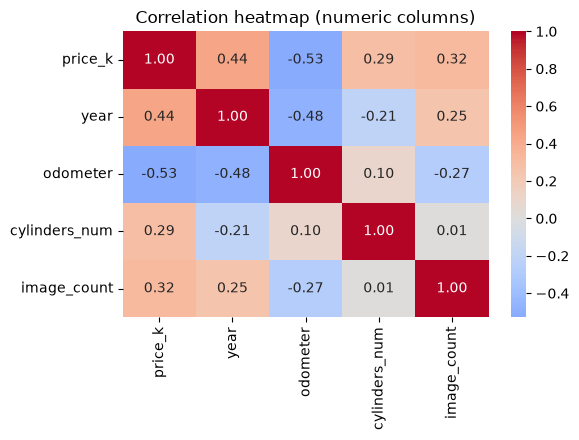

In [3]:
num = ["price_k","year","odometer","cylinders_num","image_count"]
plt.figure(figsize=(6,4.5))
sns.heatmap(df[num].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation heatmap (numeric columns)"); plt.tight_layout(); plt.show()

**What it shows.** Odometer has the strongest correlation with price (-0.51), then year (+0.43). Year and odometer are also correlated with each other (-0.47), because newer cars have fewer miles. Cylinders (0.28) and image count (0.31) have weaker links.
**Decision.** I keep `year` and `odometer` as the main numeric inputs. The overlap between them means a linear model will split the effect between the two. I drop `image_count`: its correlation is probably a side effect of dealers posting more photos, and a buyer cannot supply it when asking for a price estimate.

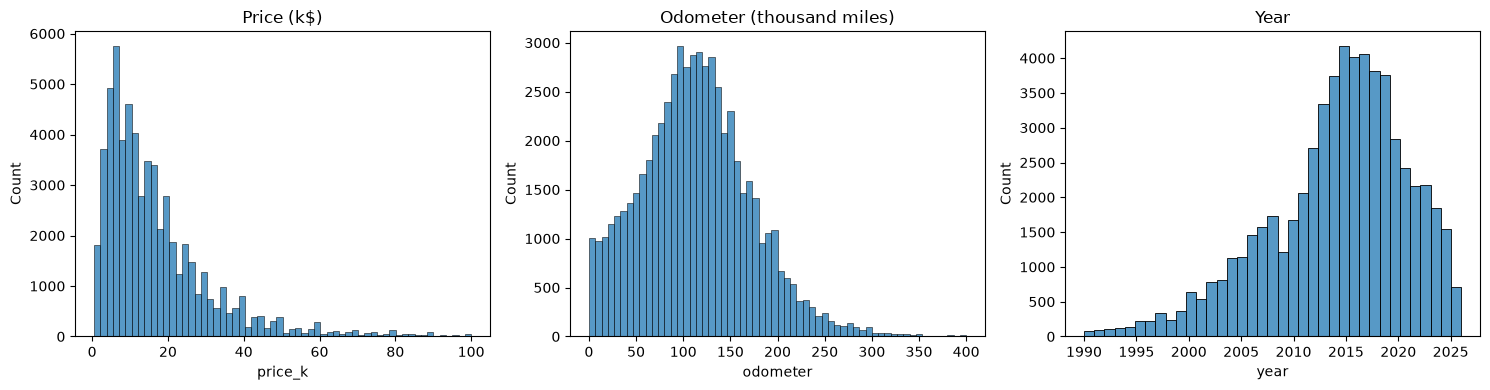

price skew: 2.05 | odometer skew: 0.49


In [4]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(df.price_k, bins=60, ax=ax[0]); ax[0].set_title("Price (k$)")
sns.histplot(df.odometer/1000, bins=60, ax=ax[1]); ax[1].set_title("Odometer (thousand miles)")
sns.histplot(df.year, bins=37, ax=ax[2]); ax[2].set_title("Year")
plt.tight_layout(); plt.show()
print("price skew:", round(df.price_k.skew(),2), "| odometer skew:", round(df.odometer.skew(),2))

**What it shows.** Price is right-skewed (skew about 2): most cars are cheap, with a long tail of expensive ones. Odometer is mildly skewed and year is concentrated in recent models.
**Decision.** I standardize the numeric features so the large odometer scale does not dominate gradient descent, and I express price in thousands of dollars so SGD learns stably. The expensive tail will make the MSE large for every model, especially the linear ones.

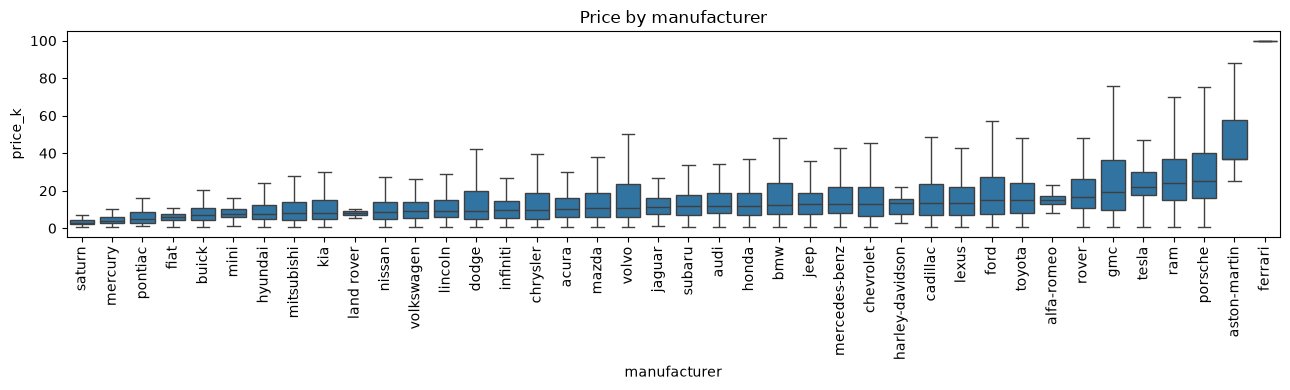

In [5]:
order = df.groupby("manufacturer").price_k.median().sort_values().index
plt.figure(figsize=(13,4)); sns.boxplot(data=df, x="manufacturer", y="price_k", order=order, showfliers=False)
plt.xticks(rotation=90); plt.title("Price by manufacturer"); plt.tight_layout(); plt.show()

**What it shows.** The median price differs strongly between brands, with luxury and truck brands well above economy brands.
**Decision.** I keep `manufacturer` and one-hot encode it. A tree model can combine brand with year and mileage, which a straight line cannot.

## 3. Feature engineering
- **Dropped:** `paint_color` (weak relationship with price) and `image_count` (it reflects how dealers post, and a buyer cannot supply it), `state` (51 values, would add many sparse columns for little gain), `seller_type` (dealer vs owner, mostly a listing artefact), plus id/url/description/VIN style columns that are identifiers or free text.
- **Kept (10 inputs):** `year`, `odometer` (numeric) and `manufacturer`, `condition`, `cylinders`, `fuel`, `transmission`, `drive`, `type`, `title_status` (categorical).
- Missing categorical values were filled with `"unknown"` instead of dropping rows, because `condition` is missing in about half the listings.

In [6]:
NUM = ["year","odometer"]
CAT = ["manufacturer","condition","cylinders","fuel","transmission","drive","type","title_status"]
FEATURES = NUM + CAT
X, y = df[FEATURES], df.price_k
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RNG)
pre = ColumnTransformer([("num", StandardScaler(), NUM),
                         ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT)])
Xtr = pre.fit_transform(X_train)   # scaler and encoder learn from the training set only
Xte = pre.transform(X_test)
print(X_train.shape, X_test.shape, "->", Xtr.shape[1], "features after encoding")

(48000, 10) (12000, 10) -> 93 features after encoding


Categorical columns become 0/1 columns with one-hot encoding. The scaler and encoder are fitted on the training rows only (`fit_transform` on train, `transform` on test), so no information from the test set leaks in.

### Feature importance (quick random forest)

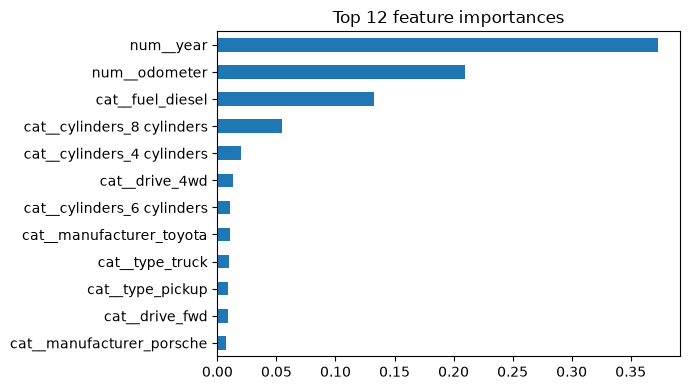

In [7]:
rf_probe = RandomForestRegressor(n_estimators=60, max_depth=18, n_jobs=-1, random_state=RNG).fit(Xtr, y_train)
names = pre.get_feature_names_out()
imp = pd.Series(rf_probe.feature_importances_, index=names).sort_values(ascending=False).head(12)
imp.iloc[::-1].plot.barh(figsize=(7,4), title="Top 12 feature importances"); plt.tight_layout(); plt.show()

The most important features are `year` (0.38) and `odometer` (0.21), then `fuel_diesel` (0.14, diesel trucks are expensive) and engine size (`cylinders`). This agrees with the heatmap and the boxplot, so the 10 chosen inputs carry the signal.

## 4. Train and compare four models

### 4a. SGDRegressor: tuning the learning rate, regularization and epochs

In [8]:
def run_sgd(eta0, alpha, epochs, penalty="l2"):
    m = SGDRegressor(learning_rate="constant", eta0=eta0, alpha=alpha, penalty=penalty,
                     random_state=RNG)
    tr, te = [], []
    for _ in range(epochs):
        m.partial_fit(Xtr, y_train)
        tr.append(mean_squared_error(y_train, m.predict(Xtr)))
        te.append(mean_squared_error(y_test, m.predict(Xte)))
    return m, tr, te

rows = []
for eta0 in [0.0001, 0.001, 0.01, 0.05]:
    for alpha in [1e-6, 1e-4, 1e-2, 1]:
        _, tr, te = run_sgd(eta0, alpha, 30)
        rows.append((eta0, alpha, tr[-1], te[-1]))
grid = pd.DataFrame(rows, columns=["eta0","alpha","train_mse","test_mse"])
print(grid.pivot(index="eta0", columns="alpha", values="test_mse").round(2))
grid.sort_values("test_mse").head(5)

alpha   0.000001  0.000100  0.010000  1.000000
eta0                                          
0.0001     78.52     78.53     79.76    133.89
0.0010     78.39     78.39     79.89    133.84
0.0100     82.64     82.62     84.55    140.39
0.0500     87.44     87.32     88.45    162.18


,eta0,alpha,train_mse,test_mse
4,0.0010,0.000001,77.092809,78.385083
5,0.0010,0.000100,77.102192,78.387066
0,0.0001,0.000001,77.334372,78.524788
1,0.0001,0.000100,77.341407,78.533165
2,0.0001,0.010000,78.446451,79.762031


In [9]:
best_row = grid.sort_values("test_mse").iloc[0]
rows = []
for ep in [1, 5, 10, 30, 60, 100]:
    _, tr, te = run_sgd(best_row.eta0, best_row.alpha, ep)
    rows.append((ep, tr[-1], te[-1]))
print(pd.DataFrame(rows, columns=["epochs","train_mse","test_mse"]).round(2))

   epochs  train_mse  test_mse
0       1      78.86     80.09
1       5      77.37     78.55
2      10      77.21     78.44
3      30      77.09     78.39
4      60      77.02     78.37
5     100      76.98     78.38


**Tuning notes.** *Learning rate (eta0):* 0.0001 and 0.001 gave nearly the same test MSE (about 78.4-78.5); 0.01 and 0.05 raised it to 82.6 and 87.4 because the steps were too large and the weights bounced around the minimum. *Regularization (alpha, L2):* values up to 0.0001 changed nothing, 0.01 was slightly worse (about 79.8) and alpha = 1 hurt a lot (about 134) because it shrank the weights too far and the model underfit. *Epochs:* the test MSE dropped from 80.1 after 1 epoch to 78.4 by 10 epochs and then stayed flat, so more than about 30 epochs gives no gain. I used eta0 = 0.001, alpha = 1e-6 and 60 epochs.

chosen eta0 = 0.001 alpha = 1e-06 epochs = 60


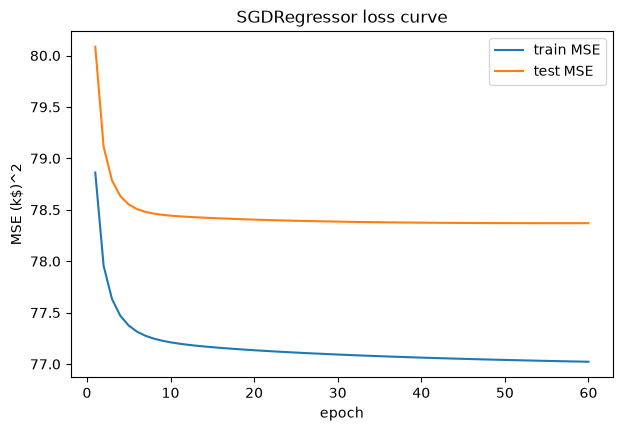

In [10]:
EPOCHS = 60
sgd, sgd_tr, sgd_te = run_sgd(best_row.eta0, best_row.alpha, EPOCHS)
print("chosen eta0 =", best_row.eta0, "alpha =", best_row.alpha, "epochs =", EPOCHS)
plt.figure(figsize=(7,4.5))
plt.plot(range(1, EPOCHS+1), sgd_tr, label="train MSE"); plt.plot(range(1, EPOCHS+1), sgd_te, label="test MSE")
plt.xlabel("epoch"); plt.ylabel("MSE (k$)^2"); plt.title("SGDRegressor loss curve"); plt.legend(); plt.show()

**Loss curve.** Train and test MSE fall quickly in the first few epochs and then flatten together at roughly 77 (train) and 78 (test). The small gap shows there is no overfitting. The high plateau shows underfitting: a straight line in the features cannot describe how price falls with age and mileage, so more epochs cannot help.

### 4b. The other three models and the comparison table

In [11]:
lin = LinearRegression().fit(Xtr, y_train)
tree = DecisionTreeRegressor(max_depth=15, min_samples_leaf=5, random_state=RNG).fit(Xtr, y_train)
forest = RandomForestRegressor(n_estimators=150, max_depth=22, min_samples_leaf=3, n_jobs=-1, random_state=RNG).fit(Xtr, y_train)

models = {"SGDRegressor": sgd, "LinearRegression": lin, "DecisionTree": tree, "RandomForest": forest}
results = {}
for name, m in models.items():
    results[name] = {"train_mse": mean_squared_error(y_train, m.predict(Xtr)),
                     "test_mse": mean_squared_error(y_test, m.predict(Xte))}
res = pd.DataFrame(results).T
res["test_rmse_$"] = np.sqrt(res.test_mse) * 1000
best_name = res.test_mse.idxmin()
print("Best model (lowest test MSE):", best_name)
res.round(3).sort_values("test_mse")

Best model (lowest test MSE): RandomForest


,train_mse,test_mse,test_rmse_$
RandomForest,16.255,35.496,5957.862
DecisionTree,30.347,49.770,7054.796
LinearRegression,76.561,78.186,8842.286
SGDRegressor,77.023,78.370,8852.683


**Best model: RandomForest** (test MSE 35.5, about $5,960 RMSE), chosen because it has the lowest test MSE. The decision tree (49.8) is second. The two linear models are nearly identical (78.2 and 78.4), which confirms that SGD reached the closed-form solution and that the limit is the linear form, not the optimizer. The relationship between price and year, mileage and brand is non-linear with interactions, which trees handle well. The forest's train MSE (16.3) is lower than its test MSE (35.5), so it overfits somewhat, but it still beats every other model on unseen data.

## 5. Scatter plots: before and after the fitted line

feature most correlated with price: odometer


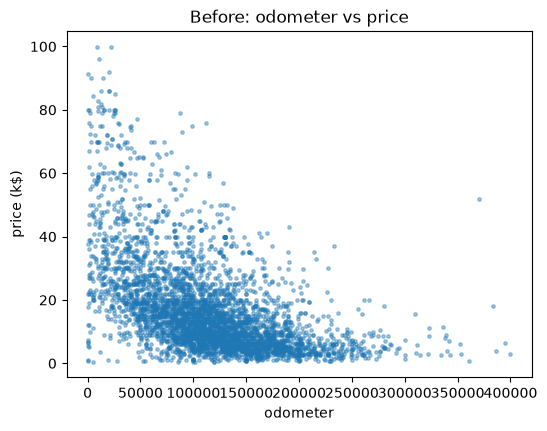

In [12]:
top = df[["price_k","year","odometer"]].corr()["price_k"].drop("price_k").abs().idxmax()
print("feature most correlated with price:", top)
s = df.sample(4000, random_state=RNG)
plt.figure(figsize=(6,4.5)); plt.scatter(s[top], s.price_k, s=6, alpha=.4)
plt.xlabel(top); plt.ylabel("price (k$)"); plt.title(f"Before: {top} vs price"); plt.show()

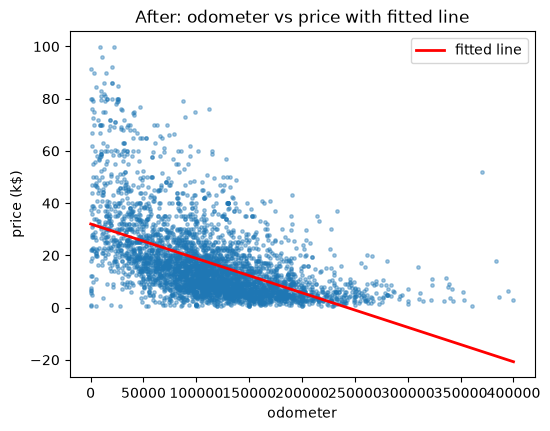

In [13]:
one = LinearRegression().fit(X_train[[top]], y_train)     # one-feature model, for this plot only
xs = np.linspace(df[top].min(), df[top].max(), 100)
plt.figure(figsize=(6,4.5)); plt.scatter(s[top], s.price_k, s=6, alpha=.4)
plt.plot(xs, one.predict(pd.DataFrame({top: xs})), color="red", lw=2, label="fitted line")
plt.xlabel(top); plt.ylabel("price (k$)"); plt.title(f"After: {top} vs price with fitted line"); plt.legend(); plt.show()

**Reading the plots.** The first scatter shows odometer against price: a noisy cloud with price tending to fall as mileage rises. The red line in the second plot is the best one-feature straight line. It captures the downward trend but misses the curve and the spread, which is why single-feature linear regression is a weak predictor here.

## 6. Save the best model with its preprocessing and predict one row

In [14]:
def make_regressor(name):
    if name == "SGDRegressor":
        return SGDRegressor(learning_rate="constant", eta0=best_row.eta0, alpha=best_row.alpha,
                            max_iter=EPOCHS, tol=None, random_state=RNG)
    if name == "LinearRegression":
        return LinearRegression()
    if name == "DecisionTree":
        return DecisionTreeRegressor(max_depth=15, min_samples_leaf=5, random_state=RNG)
    return RandomForestRegressor(n_estimators=150, max_depth=22, min_samples_leaf=3, n_jobs=-1, random_state=RNG)

pipe = Pipeline([("pre", ColumnTransformer([("num", StandardScaler(), NUM),
                                            ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT)])),
                 ("model", make_regressor(best_name))]).fit(X_train, y_train)
print("pipeline test MSE:", mean_squared_error(y_test, pipe.predict(X_test)))
joblib.dump(pipe, "../API/best_model.pkl", compress=3)

# small copy of the training rows, used by /retrain when the best model is not SGD
train_out = X_train.assign(price_k=y_train).sample(10_000, random_state=RNG)
train_out.to_csv("../API/train_data.csv", index=False)
print("model size MB:", round(os.path.getsize("../API/best_model.pkl")/1e6, 1))

pipeline test MSE: 35.49612003923273
model size MB: 42.5


In [15]:
def predict_one(row_index=0, path="../API/best_model.pkl"):
    """Load the saved pipeline and predict the price (in dollars) for one row of the test set."""
    model = joblib.load(path)
    row = X_test.iloc[[row_index]]
    pred = model.predict(row)[0] * 1000
    actual = y_test.iloc[row_index] * 1000
    print(row.iloc[0].to_dict()); print(f"predicted ${pred:,.0f}  actual ${actual:,.0f}")
    return pred
predict_one(0)

{'year': 2007.0, 'odometer': 188741.0, 'manufacturer': 'ford', 'condition': 'good', 'cylinders': '8 cylinders', 'fuel': 'gas', 'transmission': 'automatic', 'drive': '4wd', 'type': 'pickup', 'title_status': 'clean'}
predicted $5,910  actual $8,995


np.float64(5910.495611485559)